In [5]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload
import sys
import os
# sys.path.append(os.path.relpath("../utility"))
from PileUp_analysis.utility.functions import *
# sys.path.append(os.path.relpath("../src"))
from PileUp_analysis.src.analysis import *
from PileUp_analysis.src.dataset import *
from PileUp_analysis.src.high_analysis import *


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [6]:
for channel in [5]:#[3,5,9,11,13,15,17,19]:
    mean, bslspec = get_meanpulse_ANPS(channel)
    data_single,data_pileup,dt_pileup,dE_pileup,datas_pileup = create_data_sets(channel,-1,pos_prefix="_bis")
    transf_OF,_ = compute_transfer_simple(mean, bslspec)
    
    best_params,_=get_best_param(channel)
    mg = modified_gaussian(np.fft.fftfreq(2000,1e-4),best_params["A"],np.log(best_params["f0"]),best_params["sigma"],1)
    transf_PU,_ = compute_transfer_simple(mean,mg*bslspec )
    
    filtered_amp_single, argmax_single = get_interpolate_filtered_amp(data_single, transf_PU, arg_max=1999)
    fitted_amp_single = get_interpolate_fitted_amp(data_single, transf_PU, argmax_single, mean,jitter = 150)
    chi2_single = get_interpolate_chi2(data_single, transf_PU, argmax_single, mean)
    
    filtered_amp_pileup, argmax_pileup = get_interpolate_filtered_amp(data_pileup, transf_PU, arg_max=1999)
    fitted_amp_pileup = get_interpolate_fitted_amp(data_pileup, transf_PU, argmax_pileup, mean,jitter = 150)
    chi2_pileup = get_interpolate_chi2(data_pileup, transf_PU, argmax_pileup, mean)

In [7]:
from functions import *
PSD_single = filtered_amp_single[:,0]/fitted_amp_single.numpy()
PSD_pileup = filtered_amp_pileup[:,0]/fitted_amp_pileup.numpy()
cut = np.percentile(PSD_single,10)
rp = np.sum(PSD_pileup<cut)/len(PSD_pileup)
print(rp,calculate_BI(rp,0.8)*1e5)

0.7882 5.586684399186376


[(15000,), (15000,), (15000,), (15000,)]
5 0.8392 0.7668 6.151155816290191


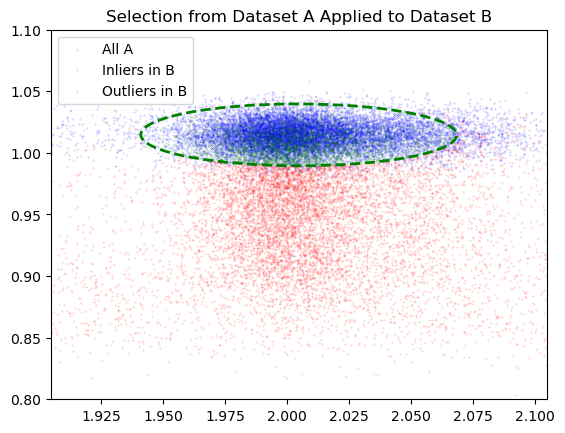

In [8]:
xA =  chi2_single
yA = filtered_amp_single[:,0]/fitted_amp_single.numpy()
xB =  chi2_pileup
yB =  filtered_amp_pileup[:,0]/fitted_amp_pileup.numpy()
print([a.shape for a in [xA,yA,xB,yB]])
ch2_max,chi2_min = np.median(chi2_single)+0.1,np.median(chi2_single)-0.1
sel= (yA<1.05)&(yA>0.8)&(xA<ch2_max)&(xA>chi2_min) #
xA,yA,xB,yB = xA[sel],yA[sel],xB[sel],yB[sel]
dataA = np.column_stack((xA, yA))
# Compute ellipse parameters from dataset A
mean_A = np.median(dataA, axis=0)
cov_A = np.cov(dataA, rowvar=False)
inliers_A, outliers_A = get_inliers_outliers(xA, yA, mean_A, cov_A, confidence=0.9)
# Get inliers/outliers in B based on ellipse from A
inliers_B, outliers_B = get_inliers_outliers(xB, yB, mean_A, cov_A, confidence=0.9)
print(channel, len(inliers_A)/len(chi2_single),1-len(inliers_B)/len(chi2_pileup),calculate_BI(1-len(inliers_B)/len(chi2_pileup),0.8)*1e5)

fig, ax = plt.subplots()
ax.scatter(xA, yA, s=0.1, c='blue', label='All A', alpha=0.3)
ax.scatter(inliers_B[:, 0], inliers_B[:, 1], s=0.1, c='green', label='Inliers in B', alpha=0.3)
ax.scatter(outliers_B[:, 0], outliers_B[:, 1], s=0.1, c='red', label='Outliers in B', alpha=0.3)
draw_confidence_ellipse(mean_A, cov_A, confidence=0.90, ax=ax, linestyle='--',edgecolor="g")
ax.legend()
plt.title("Selection from Dataset A Applied to Dataset B")

plt.xlim(mean_A[0]-0.1,mean_A[0]+0.1)
plt.ylim(0.8,1.1)
plt.show()
# plt.plot(chi2_single,filtered_amp_single[:,0]/fitted_amp_single,ls="",marker=".",ms=0.5)
# plt.plot(chi2_pileup,filtered_amp_pileup[:,0]/fitted_amp_pileup,ls="",marker=".",ms=0.5,c="r")
# plt.ylim(0.9,1.04)
# plt.xlim(1.9,2.1)
